In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Reporte Ejecutivo de Excepciones:
# Transformamos los hallazgos técnicos en KPIs de gestión. 
# El objetivo es reducir la carga operativa de conciliación manual al mínimo.

# --- 0. CONFIGURACIÓN E INTEGRACIÓN DE MÓDULOS ---
# Establecemos una estética visual profesional y moderna (Seaborn).
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (14, 6)

# Implementamos rutas dinámicas (Pathlib) para asegurar que el proyecto 
# sea ejecutable en cualquier entorno (Windows/Linux) sin errores de ruta.
base_dir = Path.cwd().resolve()
if base_dir.name == "notebooks":
    base_dir = base_dir.parent

ruta_mayor = base_dir / "data" / "raw" / "libro_mayor.csv"
ruta_conciliados = base_dir / "data" / "processed" / "conciliados_final.csv"
ruta_pendientes = base_dir / "data" / "processed" / "Partidas_Pendientes_Marzo.xlsx"

# Carpeta de salida para evidencias visuales (README y documentación).
ruta_graficos = base_dir / "docs" / "img"
ruta_graficos.mkdir(parents=True, exist_ok=True)

# Control de Disponibilidad de Datos:
# Antes de generar el reporte, validamos la existencia de la evidencia 
# procesada en los notebooks anteriores.
archivos_obligatorios = [ruta_mayor, ruta_pendientes]
faltantes = [str(p) for p in archivos_obligatorios if not p.exists()]
if faltantes:
    raise FileNotFoundError(f"Error Crítico: Faltan archivos de evidencia: {faltantes}")

# Consolidamos la información para el análisis visual
df_mayor = pd.read_csv(ruta_mayor, parse_dates=["fecha"])
df_pend_mayor = pd.read_excel(ruta_pendientes, sheet_name="Revisar_en_Mayor")
df_pend_banco = pd.read_excel(ruta_pendientes, sheet_name="Revisar_en_Banco")

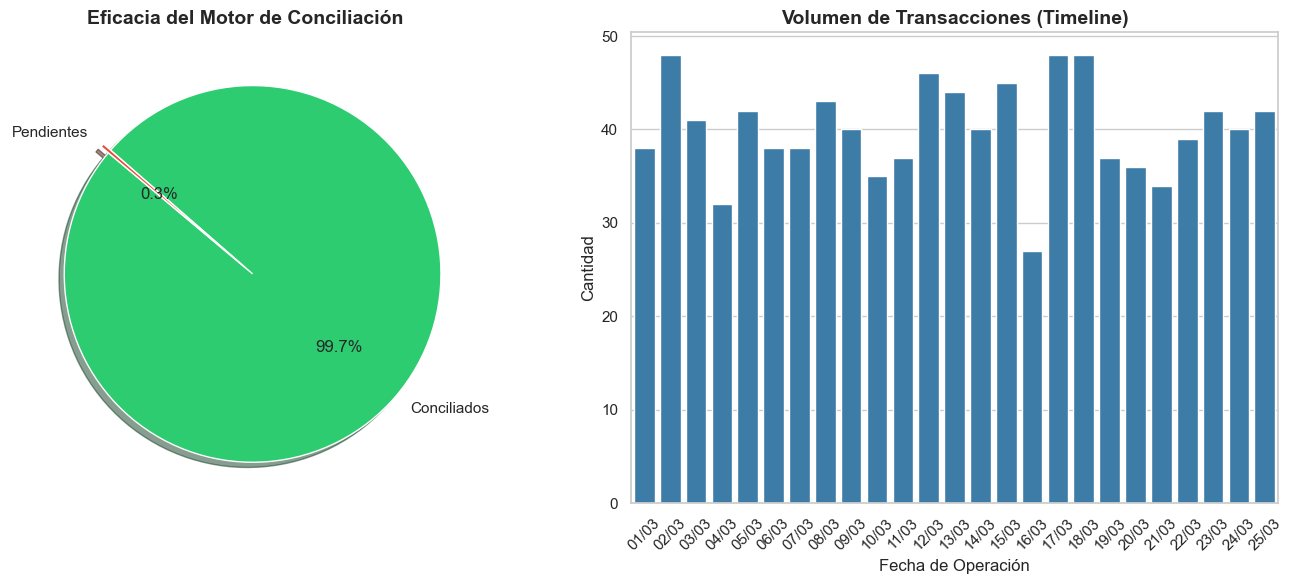

📊 INFORME DE GESTIÓN DE AUDITORÍA: AUDITSYNC
Capacidad del Motor: 99.70% de efectividad.
Monto Total Auditado: $16,125,215.02 pesos.
Pendientes para Supervisión: 3 casos aislados.
📁 Gráfico de torta exportado en: D:\Dev\DataPortfolio\AuditSync_Banking\docs\img\eficacia_motor_conciliacion.png
📁 Gráfico de barras exportado en: D:\Dev\DataPortfolio\AuditSync_Banking\docs\img\volumen_transacciones_timeline.png


In [11]:
# --- 1. PROCESAMIENTO DE KPIs (INDICADORES CLAVE DE DESEMPEÑO) ---

# Verificamos la fuente de datos de conciliados para asegurar la trazabilidad
if ruta_conciliados.exists():
    df_conciliados = pd.read_csv(ruta_conciliados)
    total_match = len(df_conciliados)
    monto_recuperado = df_conciliados["monto"].sum()
else:
    # Lógica de Seguridad (Fallback): Estimación basada en registros no conciliados
    total_match = max(len(df_mayor) - len(df_pend_mayor), 0)
    monto_recuperado = df_mayor["monto"].sum() - df_pend_mayor["monto"].sum()

total_pendientes = len(df_pend_mayor) + len(df_pend_banco)
denominador_efectividad = total_match + total_pendientes
efectividad = (total_match / denominador_efectividad) if denominador_efectividad else 0

# --- 2. DASHBOARD DE GESTIÓN (ANÁLISIS DE EXCEPCIONES) ---
fig, (ax1, ax2) = plt.subplots(1, 2)

# Gráfico A: Nivel de Eficacia Operativa
# Visualizamos la capacidad de automatización del motor. 
# El objetivo es aislar el "ruido" para que el capital humano se enfoque solo en las excepciones.
labels = ["Conciliados", "Pendientes"]
sizes = [total_match, total_pendientes]
colores_estado = ["#2ecc71", "#e74c3c"]
ax1.pie(
    sizes,
    labels=labels,
    autopct="%1.1f%%",
    startangle=140,
    colors=colores_estado,  # Código de color: Éxito vs Alerta
    explode=(0.05, 0),
    shadow=True,
    wedgeprops={"linewidth": 1, "edgecolor": "white"},
)
ax1.set_title("Eficacia del Motor de Conciliación", fontsize=14, fontweight="bold")

# Gráfico B: Análisis de Carga de Trabajo (Volumen Diario)
# Identificamos picos transaccionales que puedan saturar el flujo de caja o el clearing.
movimientos_dia = (
    df_mayor.assign(dia=df_mayor["fecha"].dt.floor("D"))
    .groupby("dia")
    .size()
    .sort_index()
    .reset_index(name="cantidad")
)
movimientos_dia["dia_str"] = movimientos_dia["dia"].dt.strftime("%d/%m")
sns.barplot(data=movimientos_dia, x="dia_str", y="cantidad", ax=ax2, color="#2c7fb8")
ax2.set_title("Volumen de Transacciones (Timeline)", fontsize=14, fontweight="bold")
ax2.set_ylabel("Cantidad")
ax2.set_xlabel("Fecha de Operación")
ax2.tick_params(axis="x", rotation=45)

# Exportamos gráficos individuales para README y documentación ejecutiva.
ruta_torta = ruta_graficos / "eficacia_motor_conciliacion.png"
ruta_barras = ruta_graficos / "volumen_transacciones_timeline.png"

fig_torta, ax_torta = plt.subplots(figsize=(7, 6))
ax_torta.pie(
    sizes,
    labels=labels,
    autopct="%1.1f%%",
    startangle=140,
    colors=colores_estado,
    explode=(0.05, 0),
    shadow=True,
    wedgeprops={"linewidth": 1, "edgecolor": "white"},
)
ax_torta.set_title("Eficacia del Motor de Conciliación", fontsize=14, fontweight="bold")
fig_torta.tight_layout()
fig_torta.savefig(ruta_torta, dpi=160, bbox_inches="tight")
plt.close(fig_torta)

fig_barras, ax_barras = plt.subplots(figsize=(11, 5))
sns.barplot(data=movimientos_dia, x="dia_str", y="cantidad", ax=ax_barras, color="#2c7fb8")
ax_barras.set_title("Volumen de Transacciones (Timeline)", fontsize=14, fontweight="bold")
ax_barras.set_ylabel("Cantidad")
ax_barras.set_xlabel("Fecha de Operación")
ax_barras.tick_params(axis="x", rotation=45)
fig_barras.tight_layout()
fig_barras.savefig(ruta_barras, dpi=160, bbox_inches="tight")
plt.close(fig_barras)

plt.tight_layout()
plt.show()

# --- 3. RESUMEN EJECUTIVO (ENTREGABLE FINAL) ---
print("=" * 60)
print("📊 INFORME DE GESTIÓN DE AUDITORÍA: AUDITSYNC")
print("=" * 60)
print(f"Capacidad del Motor: {efectividad:.2%} de efectividad.")
print(f"Monto Total Auditado: ${monto_recuperado:,.2f} pesos.")
print(f"Pendientes para Supervisión: {total_pendientes} casos aislados.")
print(f"📁 Gráfico de torta exportado en: {ruta_torta}")
print(f"📁 Gráfico de barras exportado en: {ruta_barras}")
print("=" * 60)